In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sultanlar.data import load_matches, team_names
from sultanlar.elo import run_elo
from sultanlar.simulation import simulate_match

In [ ]:
df = load_matches()     # the workbook plus the active season from active_season_matches.csv
df.head()

In [ ]:
matches_elo, ratings = run_elo(df)     # settings come from config.json

current_teams = set(df[df.season == df.season.max()].home_id)

elo_df = (
    pd.DataFrame(ratings.items(), columns=["team_id", "elo"])
      .assign(team=lambda d: d.team_id.map(team_names()),
              in_league_now=lambda d: d.team_id.isin(current_teams))
      .sort_values("elo", ascending=False)
      .reset_index(drop=True)
)
elo_df.index += 1          # rank starting at 1
elo_df[elo_df.in_league_now]

In [20]:
# Rating at the end of each season (NaN = team not in the league that season)
seasons = sorted(df.season.unique())
season_end = pd.DataFrame({s: pd.Series(run_elo(df[df.season <= s])[1]) for s in seasons})

played = pd.DataFrame({s: season_end.index.isin(df[df.season == s].home_id) for s in seasons},
                      index=season_end.index)
season_end = season_end.where(played).round(0)
season_end.sort_values(seasons[-1], ascending=False)

,2021-22,2022-23,2023-24,2024-25,2025-26
VAK,1949.0,1910.0,1861.0,2004.0,1958.0
FEN,1854.0,1920.0,1982.0,1838.0,1868.0
ECZ,1816.0,1866.0,1891.0,1812.0,1729.0
ZER,NaN,NaN,NaN,1627.0,1678.0
GS,1658.0,1518.0,1609.0,1711.0,1627.0
GOZ,NaN,NaN,NaN,NaN,1585.0
KUZ,1404.0,1289.0,1666.0,1584.0,1513.0
ARS,NaN,NaN,NaN,1408.0,1482.0
THY,1636.0,1663.0,1647.0,1542.0,1421.0
NIL,1233.0,1635.0,1514.0,1424.0,1413.0


In [21]:
# How good are the predictions? Skip 2021-22, where everyone still starts at 1500
test = matches_elo[matches_elo.season != seasons[0]]
y = (test.home_sets > test.away_sets).astype(int)
p = test.p_home.clip(1e-6, 1 - 1e-6)

log_loss = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
accuracy = ((p > 0.5) == y).mean()
print(f"log loss {log_loss:.3f}   accuracy {accuracy:.1%}   (coin flip: log loss 0.693, home team always: {y.mean():.1%})")

log loss 0.418   accuracy 80.5%   (coin flip: log loss 0.693, home team always: 52.4%)


         matches predicted actual     gap
group                                    
0–10%        105      5.4%   1.9%   -3.5%
10–20%        76     14.7%  17.1%   +2.4%
20–30%        48     24.5%  20.8%   -3.7%
30–40%        67     34.9%  23.9%  -11.0%
40–50%        87     45.2%  43.7%   -1.5%
50–60%        63     55.4%  57.1%   +1.8%
60–70%        79     65.1%  68.4%   +3.3%
70–80%        64     75.1%  76.6%   +1.5%
80–90%        89     84.8%  89.9%   +5.1%
90–100%      123     95.0%  99.2%   +4.2%


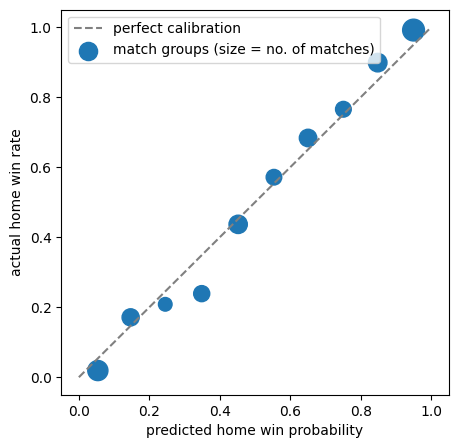

In [22]:
# Calibration: when the model says 75%, does the home team win about 75% of the time?

bins = np.arange(0, 1.01, 0.1)
calib = (
    pd.DataFrame({"p": p, "won": y})
      .assign(group=lambda d: pd.cut(d.p, bins, labels=[f"{int(a*100)}–{int(b*100)}%" for a, b in zip(bins[:-1], bins[1:])]))
      .groupby("group", observed=True)
      .agg(matches=("won", "size"), predicted=("p", "mean"), actual=("won", "mean"))
)
calib["gap"] = calib.actual - calib.predicted
print(calib.assign(predicted=calib.predicted.map("{:.1%}".format),
                   actual=calib.actual.map("{:.1%}".format),
                   gap=calib.gap.map("{:+.1%}".format)))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.scatter(calib.predicted, calib.actual, s=calib.matches * 2, label="match groups (size = no. of matches)")
ax.set_xlabel("predicted home win probability")
ax.set_ylabel("actual home win rate")
ax.legend(loc="upper left")
plt.show()

In [ ]:
import itertools

def log_loss_of(df, score_seasons, **params):
    games, _ = run_elo(df, **params)
    test = games[games.season.isin(score_seasons)]
    y = (test.home_sets > test.away_sets).astype(int)
    p = test.p_home.clip(1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()

seasons = sorted(df[df.use_for_elo == "Y"].season.unique())
burn_in, tune, holdout = seasons[0], seasons[1:-1], seasons[-1:]

# Tune K and S together, keeping the others at their config.json values for now.
# Score only the tuning seasons; the last season stays untouched.
results = []
for K, S in itertools.product(range(10, 121, 10), [250, 300, 350, 400]):
    ll = log_loss_of(df, tune, K=K, S=S)
    results.append({"K": K, "S": S, "log_loss": ll})

results = pd.DataFrame(results).sort_values("log_loss")
print(results.head(10))

best = results.iloc[0]
print("holdout log loss:", log_loss_of(df, holdout, K=best.K, S=best.S))

In [ ]:
# Monte Carlo match simulation between the two highest-rated teams
home, away = elo_df[elo_df.in_league_now].team_id.iloc[:2]
sim = simulate_match(home, away, ratings, seed=42)
print(f"{home} vs {away}: home win {sim['home_win']:.1%}   per-set win probability {sim['p_set']:.1%}")
print(sim["scorelines"].map("{:.1%}".format))